In [1]:
import numpy

# Constants
R_jupiter_equator = 71492  # Jupiter's equatorial radius in km
R_jupiter_polar = 66854    # Jupiter's polar radius in km

def cartesian_to_polar(x, y):
    # Convert Cartesian (x, y) to polar (r, theta)
    r = np.sqrt(x**2 + y**2)  # Distance from the origin
    theta = np.arctan2(y, x)    # Angle in radians
    return r, theta

def polar_to_lat_lon(r, theta):
    # Convert polar (r, theta) to latitude and longitude
    lon = np.degrees(theta)  # Latitude in degrees
    lat = (r / R_jupiter_polar) * (180 / np.pi)  # Longitude in degrees
    return lat, lon

def cartesian_to_lat_lon(x, y):
    # Convert Cartesian (x, y) to latitude and longitude
    r, theta = cartesian_to_polar(x, y)
    lat, lon = polar_to_lat_lon(r, theta)
    return [lat, lon]

def convert_to_system_III_west(longitude):
    system_III_west_longitude = 360 - longitude
    return system_III_west_longitude

def trans_latlon_to_xy(lat, lon):
    # Jupiter's radii in km
    R_equator = 71492.0  # Equatorial radius
    R_polar = 66854.0    # Polar radius

    # Convert lat and lon to radians
    lat_rad = np.radians(lat)
    lon_rad = np.radians(lon)

    # Calculate the radius for each latitude (ellipsoidal shape of Jupiter)
    R = R_equator * np.cos(lat_rad)**2 + R_polar * np.sin(lat_rad)**2

    # Compute Cartesian coordinates
    x = R * np.cos(lat_rad) * np.cos(lon_rad)
    y = R * np.cos(lat_rad) * np.sin(lon_rad)
    return x, y

In [2]:
# read ../profiles_in_grid_dry.h5

import numpy as np
import h5py


profile=h5py.File("../profiles_in_grid_dry.h5", "r")
nh3ppm=profile["ppm_NH3"][:]
profile.close() 

nh3ppm[nh3ppm==0]=np.nan


mainout=h5py.File("../cpc_dry/bin/juno_forward_mwr_polarmean-main.nc", "r")
pressure=mainout["press"][0,:,0,0]*1E-5  # in bar
mainout.close()


with h5py.File("../cpc_dry/bin/juno_mwr_forward_polarmean_profiles.h5", "r") as f:
    bg_nh3_ppm=f["nh3_ppm"][:]
    # bg_h2o_ppm=f["h2o_ppm"][:]
    bg_temp=f["temp"][:]
    # bg_theta=f["theta"][:]
    # bg_nh3_sh=f["nh3_sh"][:]
    # bg_nh3_rh=f["nh3_rh"][:]


print("nh3ppm shape:", nh3ppm.shape)  # (100, 100, 1600)
print("pressure levels:", pressure.shape) # 0: 8100bar, 1600: 0.00127bar


# input the grid coordinates
with h5py.File("../observation/tb_anomaly_grided_PJ51_PJ61_FA02.h5", "r") as h5f:
    anomaly=h5f["anomaly"][:]
    lon2d=h5f["longitude"][:]
    lat2d=h5f["latitude"][:]
    grid_x=h5f["x"][:]
    grid_y=h5f["y"][:]

print(anomaly.shape) # (6, 100, 100)
print(lon2d.shape) # (100, 100)

x_cor =grid_x[0,:]
y_cor =grid_y[:,0]

nh3ppm shape: (100, 100, 1600)
pressure levels: (1600,)
(6, 100, 100)
(100, 100)


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
from scipy.ndimage import gaussian_filter


longitude = np.array([0, 90, 180, 270, 360])
system_III_west_longitude = convert_to_system_III_west(longitude)
print(system_III_west_longitude)



# prepare the for panel a
def plot_panela(ax):

    def plot_cross_section(ax, var3d, press_levels,x,y, x_line, y_line, lons, lats, xref):
        t_values = np.arange(0, len(x_line),1 )
        cross_section = np.zeros((len(press_levels), len(t_values)))
        for i, t in enumerate(t_values):
            x_idx = np.argmin(np.abs(x - x_line[i]))
            y_idx = np.argmin(np.abs(y - y_line[i]))
            cross_section[:, i] = var3d[:, x_idx, y_idx]

        # Plot the cross-section
        X, Y = np.meshgrid(t_values, press_levels)


        # Smooth the cross-section data using a Gaussian filter
        cross_section = gaussian_filter(cross_section, sigma=2)
        levels = [0, -10, -20, -30, -40, -50, -60, -70, -80, -90, -100][::-1]

        cont = ax.contourf(X, Y, cross_section, cmap='Blues_r', levels=np.linspace(-100, 0, 225), extend='min')
        cbar = fig.colorbar(cont, ax=ax, orientation='vertical', pad=0.02)
        cbar.set_ticks(levels[::2])
        cbar.set_ticklabels(levels[::2], fontsize=10)
        cbar.ax.set_title('      [ppmv]', pad=7, fontsize=12)

        contlin = ax.contour(X, Y, cross_section, levels=levels, colors='gray', linewidths=0.5, alpha=1, linestyles='dashed')
        ax.clabel(contlin, contlin.levels[6:], inline=True, fontsize=9, fmt='%1.0f', use_clabeltext=True, colors='k')
        # ax.clabel(contlin, contlin.levels, inline=True, fontsize=9, fmt='%1.0f', use_clabeltext=True)

        for ref in xref:
            ax.axvline(ref, color='gray', linestyle='--', linewidth=0.5)

        ax.set_yscale('log')   
        ax.set_ylim(10, 0.1) 

        ax.set_yticks([10, 1, 0.1])
        ax.set_yticklabels([10, 1.0, 0.1], fontsize=10)
        ax.set_ylabel('Pressure [bar]', fontsize=14)


        # ticks=t_values[::50]
        ax.set_xticks(xref)
        label=[""]*len(xref)
        label[1:]=[f"{convert_to_system_III_west(lon):.0f}°W\n{90-lat:.1f}°N" for lon, lat in zip(lons[xref[1:]], lats[xref[1:]])]
        label[0]=""
        ax.set_xticklabels(label, fontsize=10)
        # ax.set_xlabel('Along CPC Polygon (System III, west longitude, planetocentric latitude)', fontsize=14)


    x_cor =grid_x[0,:]
    y_cor =grid_y[:,0]

    ppm_data0=nh3ppm[:,:,500:1200].transpose(2,1,0)

    pressure1 = pressure[500:1200]

    refNH3 = bg_nh3_ppm[500:1200] 

    print(refNH3.shape)
    print(ppm_data0.shape)
    ppm_data=ppm_data0-refNH3[:,np.newaxis,np.newaxis]
    ppm_data[ppm_data>0]=0

    lon_cpc = [15,348, 300, 255, 210, 165, 115, 75, 45, 15]
    lat_cpc = [84.3,83, 83, 82.5, 82.5, 82.8, 84, 81.5, 84, 84.3]
    t_values = np.linspace(0, 1, 100)

    xs=[]
    ys=[]
    lons=[]
    lats=[]

    
    xref=np.zeros(9)
    leg=0
    for i in range(len(lon_cpc) - 1):
        lonc = [lon_cpc[i], lon_cpc[i + 1]]
        latc = [lat_cpc[i], lat_cpc[i + 1]]
        xc, yc = trans_latlon_to_xy(latc, lonc)
        # print(xc)

        length = np.sqrt((xc[1] - xc[0])**2 + (yc[1] - yc[0])**2)
        nle=length//100

        # if xc[0] > xc[1]:
        #     x_line = np.arange(xc[0], xc[1], -10)
        # else:
        #     x_line = np.arange(xc[0], xc[1], 10)
        x_line = np.linspace(xc[0], xc[1], num=nle.astype(int))
        y_line = np.linspace(yc[0], yc[1], num=nle.astype(int))
        if i<8:
            xref[i+1] = xref[i] + len(x_line)

        lat_line, lon_line = cartesian_to_lat_lon(x_line, y_line)
        
        lon_line[lon_line<0]+=360 

        xs.append(x_line)
        ys.append(y_line)
        lons.append(lon_line)
        lats.append(lat_line)
    # print(xs)
    xs = np.concatenate(xs)

    ys = np.concatenate(ys)
    lons = np.concatenate(lons)
    lats = np.concatenate(lats)

    ppmv_sec=ppm_data[100:]
    press_sec=pressure1[100:]

    plot_cross_section(ax, ppmv_sec, press_sec, x_cor, y_cor, xs, ys, lons, lats,xref.astype(int))

    for ic, xr in enumerate(xref):
        if ic==0: continue
        ax.text(xr, 0.15, f'CPC{ic}', ha='center', va='center', fontweight='bold', fontsize=12)
    ax.set_title('NH$_3$ Concentration Anomaly', loc='center', fontsize=14)
    ax.text(-0.05, 1.1, 'a', ha='center', va='center', fontweight='bold',fontsize=20, transform=ax.transAxes)

[360 270 180  90   0]


In [4]:
## prepare for panel c
# plot the zonal mean profile 
lat_bins = np.arange(73, 90.25, 0.5)

print("lat_bins:", lat_bins)
# calculate zonal mean
zonal_mean = []
for i in range(len(lat_bins)):
    lat_min = lat_bins[i-1]
    lat_max = lat_bins[i]
    mask = (lat2d >= lat_min) & (lat2d < lat_max)
    zonal_mean.append(np.nanmean(nh3ppm[mask, :], axis=0))

# latbin_centers =lat_bins[1:]
# lat_bins = latbin_centers

zonal_mean= np.array(zonal_mean).T # (lat, pressure)
print("zonal_mean shape:", zonal_mean.shape)  # (34, 1600)

def plot_zonal_nh3(ax):
    levels = np.array([0,10, 30., 45., 60., 75., 90., 105., 120., 135., 150., 165., 180., 195.,
                210., 225., 240., 255., 270., 285., 300., 315., 330., 340, 345, 350., 353, 355])

    # zonal_mean_data = gaussian_filter(zonal_mean_data, sigma=2)
    print(lat_bins)
    sc=ax.contourf(lat_bins, pressure, zonal_mean, levels=levels, cmap='GnBu')

    cbar = fig.colorbar(sc, ax=ax, orientation='vertical', pad=0.02)
    cbar.ax.set_title('      [ppmv]', pad=7, fontsize=12)
    cbar.set_ticks(levels[::3])
    # cbar.set_ticklabels(levels[::3], fontsize=10)
    # cbar.ax.xaxis.set_label_position('top')  # or 'right'

    levels = np.array([0,10, 30., 45., 60., 75., 90., 105., 120., 135., 150., 165., 180., 195.,
                210., 225., 240., 255., 270., 285., 300., 315., 330., 340, 345, 350., 353, 354.8, 355])
    contlin = ax.contour(lat_bins, pressure, zonal_mean, levels=levels, linewidths=0.2, alpha=1)
    ax.clabel(contlin, contlin.levels[(levels>285)], inline=True, fontsize=9, fmt='%1.0f', use_clabeltext=True)
    ax.clabel(contlin, [120,30], inline=True, fontsize=9, fmt='%1.0f', use_clabeltext=True, colors='k')




    ax.set_yscale('log')
    ax.set_ylim(10, 0.1)
    ax.set_xlim(75, 90)
    ax.set_xticks([75, 77.5, 80, 82.5, 85, 87.5, 90])
    ax.set_xticklabels([lat for lat in ['75°N', '', '80°N', '', '85°N', '', '90°N']], fontsize=10)
    ax.set_yticks([10, 1, 0.1])
    ax.set_yticklabels([10, 1.0, 0.1], fontsize=10)
    # ax.set_ylabel('Pressure [bar]', fontsize=12)
    # ax.set_xlabel('Planetocentric Latitude [°N]', fontsize=14)
    ax.set_title(r'NH$_3$ Concentration', fontsize=14)
    ax.axhline(1, color='gray', linestyle='--', linewidth=0.5)
    # ax.axhline(0.3, color='gray', linestyle='--', linewidth=0.5)
    # ax.axhline(0.1, color='gray', linestyle='--', linewidth=0.5)
    # ax.axhline(0.01, color='gray', linestyle='--', linewidth=0.5)
    ax.text(-0.05, 1.1, 'c', ha='center', va='center', fontweight='bold',fontsize=20, transform=ax.transAxes)
    

lat_bins: [73.  73.5 74.  74.5 75.  75.5 76.  76.5 77.  77.5 78.  78.5 79.  79.5
 80.  80.5 81.  81.5 82.  82.5 83.  83.5 84.  84.5 85.  85.5 86.  86.5
 87.  87.5 88.  88.5 89.  89.5 90. ]
zonal_mean shape: (1600, 35)


/tmp/ipykernel_1388147/4155233678.py:12: RuntimeWarning: Mean of empty slice
  zonal_mean.append(np.nanmean(nh3ppm[mask, :], axis=0))


In [5]:
## pseudo data

import numpy as np
import h5py


profile=h5py.File("../profile_in_grid_pseudo.h5", "r")
temp=profile["temp"][:]
profile.close() 

temp[temp<10]=np.nan



mainout=h5py.File("../cpc_dry/bin/juno_forward_mwr_polarmean-main.nc", "r")
pressure=mainout["press"][0,:,0,0]*1E-5  # in bar
mainout.close()


with h5py.File("../cpc_moist/bin/juno_mwr_forward_polarmean_profiles_pseudo.h5", "r") as f:
    bg_temp=f["temp"][:]

print("temp shape:", temp.shape)  # (100, 100, 1600)
print("pressure levels:", pressure.shape) # 0: 8100bar, 1600: 0.00127bar


temp shape: (100, 100, 1600)
pressure levels: (1600,)


In [16]:
## prepare for panel b
def plot_temp_cross_section(ax, var3d, press_levels,x,y, x_line, y_line, lons, lats, xref):
    t_values = np.arange(0, len(x_line),1 )
    cross_section = np.zeros((len(press_levels), len(t_values)))
    for i, t in enumerate(t_values):
        x_idx = np.argmin(np.abs(x - x_line[i]))
        y_idx = np.argmin(np.abs(y - y_line[i]))
        cross_section[:, i] = var3d[:, x_idx, y_idx]

    # Plot the cross-section
    X, Y = np.meshgrid(t_values, press_levels)

    levels = np.linspace(0,6,13)
    # Smooth the cross-section data using a Gaussian filter
    cross_section = gaussian_filter(cross_section, sigma=2)
    cont = ax.contourf(X, Y, cross_section, levels= np.linspace(0,6,210), cmap='Oranges', extend='neither')
    cbar=plt.colorbar(cont, ax=ax, orientation='vertical',  pad=0.02)
    cbar.ax.set_title('      [K]', pad=7, fontsize=12)
    cbar.set_ticks(np.linspace(0, 6, 7))
    cbar.set_ticklabels([f"{tick:.1f}" for tick in np.linspace(0, 6, 7)], fontsize=10)
    # cbar.set_label('Temperature [K]')

    contlin = ax.contour(X, Y, cross_section, levels=[0,1,1.5, 2,3,4,5], colors='gray', linewidths=0.5, linestyles='solid', alpha=1)
    ax.clabel(contlin, [0,1,2,3,4,5], fontsize=9, fmt='%1.0f', colors='k', use_clabeltext=True)

    for ref in xref:
        ax.axvline(ref, color='gray', linestyle='--', linewidth=0.5)

    ax.set_yscale('log')   
    ax.set_ylim(10, 0.1) 

    ax.set_yticks([10, 1, 0.1])
    ax.set_yticklabels([10, 1.0, 0.1], fontsize=10)
    ax.set_ylabel('Pressure [bar]', fontsize=14)


    # ticks=t_values[::50]
    ax.set_xticks(xref)
    label=[""]*len(xref)
    label[1:]=[f"{convert_to_system_III_west(lon):.0f}°W\n{90-lat:.1f}°N" for lon, lat in zip(lons[xref[1:]], lats[xref[1:]])]
    label[0]=""
    ax.set_xticklabels(label, fontsize=10)
    ax.set_xlabel('Along CPC Polygon (System III, west longitude, planetocentric latitude)', fontsize=14)


def plot_panel_b(ax):

    ppm_data0=temp[:,:,500:1200].transpose(2,1,0)

    pressure1 = pressure[500:1200]

    refNH3 = bg_temp[500:1200] 
    print(refNH3.shape)
    print(ppm_data0.shape)
    ppm_data=ppm_data0-refNH3[:,np.newaxis,np.newaxis]
    ppm_data[ppm_data<0]=0.

    lon_cpc = [15,348, 300, 255, 210, 165, 115, 75, 45, 15]
    lat_cpc = [84.3,83, 83, 82.5, 82.5, 82.8, 84, 81.5, 84, 84.3]
    t_values = np.linspace(0, 1, 100)

    xs=[]
    ys=[]
    lons=[]
    lats=[]

    
    xref=np.zeros(9)
    leg=0
    for i in range(len(lon_cpc) - 1):
        lonc = [lon_cpc[i], lon_cpc[i + 1]]
        latc = [lat_cpc[i], lat_cpc[i + 1]]
        xc, yc = trans_latlon_to_xy(latc, lonc)
        # print(xc)

        length = np.sqrt((xc[1] - xc[0])**2 + (yc[1] - yc[0])**2)
        nle=length//100

        # if xc[0] > xc[1]:
        #     x_line = np.arange(xc[0], xc[1], -10)
        # else:
        #     x_line = np.arange(xc[0], xc[1], 10)
        x_line = np.linspace(xc[0], xc[1], num=nle.astype(int))
        y_line = np.linspace(yc[0], yc[1], num=nle.astype(int))
        if i<8:
            xref[i+1] = xref[i] + len(x_line)

        lat_line, lon_line = cartesian_to_lat_lon(x_line, y_line)
        
        lon_line[lon_line<0]+=360 

        xs.append(x_line)
        ys.append(y_line)
        lons.append(lon_line)
        lats.append(lat_line)
    # print(xs)
    xs = np.concatenate(xs)

    ys = np.concatenate(ys)
    lons = np.concatenate(lons)
    lats = np.concatenate(lats)

    ppmv_sec=ppm_data[100:]
    press_sec=pressure1[100:]

    plot_temp_cross_section(ax, ppmv_sec, press_sec, x_cor, y_cor, xs, ys, lons, lats,xref.astype(int))

    for ic, xr in enumerate(xref):
        if ic==0: continue
        ax.text(xr, 0.15, f'CPC{ic}', ha='center', va='center', fontweight='bold', fontsize=12)
    ax.set_title('Temperature Anomaly', loc='center', fontsize=14)
    ax.text(-0.05, 1.1, 'b', ha='center', va='center', fontweight='bold',fontsize=20, transform=ax.transAxes)


In [7]:
# plot the zonal mean profile 

def plot_panel_d(ax):
    lat_bins = np.arange(73, 90.125, 0.25)

    dtemp=temp-bg_temp

    dtemp[np.isnan(dtemp)]=0.0

    print("lat_bins:", lat_bins)
    # calculate zonal mean
    zonal_mean = np.zeros((len(lat_bins), len(pressure)))  # (pressure, lat)

    for i in range(len(lat_bins)):
        lat_indices = (lat2d > lat_bins[i-1]) & (lat2d <= lat_bins[i])
        zonal_mean[i,:] = np.nanmean(dtemp[lat_indices,:], axis=0)


    zonal_mean= np.array(zonal_mean).T # (lat, pressure)
    print("zonal_mean shape:", zonal_mean.shape)  # (34, 1600)

    levels=np.linspace(-3, 3, 7)
    zonal_mean = gaussian_filter(zonal_mean, sigma=0.8)


    contour = ax.contourf(lat_bins, pressure, zonal_mean, levels=np.linspace(-3, 3, 211), cmap='RdYlBu_r')
    cbar = fig.colorbar(contour, ax=ax, orientation='vertical',  pad=0.02)

    cbar.ax.set_title('      [K]', pad=7, fontsize=12)

    cbar.set_ticks(np.linspace(-3, 3, 7))
    cbar.set_ticklabels([f"{tick:.1f}" for tick in np.linspace(-3, 3, 7)], fontsize=10)

    contlin = ax.contour(lat_bins, pressure, zonal_mean, levels=levels, colors='k', linewidths=0.3, alpha=1)
    ax.clabel(contlin, contlin.levels, inline=True, fontsize=9, fmt='%1d', use_clabeltext=True, colors='k')
    # ax.clabel(contlin, [180,60,30], inline=True, fontsize=9, fmt='%1.0f', use_clabeltext=True)


    ax.set_yscale('log')
    ax.set_ylim(10, 0.3)
    ax.set_xlim(75, 90)
    ax.set_xticks([75, 77.5, 80, 82.5, 85, 87.5, 90])
    ax.set_xticklabels([lat for lat in ['75°N', '', '80°N', '', '85°N', '', '90°N']], fontsize=10)
    ax.set_yticks([10, 1, 0.1])
    ax.set_yticklabels([10, 1.0, 0.1], fontsize=10)
    # ax.set_ylabel('Pressure [bar]', fontsize=12)
    ax.set_xlabel('Planetocentric Latitude [°N]', fontsize=14)
    ax.set_title('Temperature Anomaly', fontsize=14)
    ax.axhline(1, color='gray', linestyle='--', linewidth=0.5)
    # ax.axhline(0.3, color='gray', linestyle='--', linewidth=0.5)
    ax.axhline(0.1, color='gray', linestyle='--', linewidth=0.5)
    ax.axhline(0.01, color='gray', linestyle='--', linewidth=0.5)
    ax.text(-0.05, 1.1, 'd', ha='center', va='center', fontweight='bold',fontsize=20, transform=ax.transAxes)

(700,)
(700, 100, 100)
[73.  73.5 74.  74.5 75.  75.5 76.  76.5 77.  77.5 78.  78.5 79.  79.5
 80.  80.5 81.  81.5 82.  82.5 83.  83.5 84.  84.5 85.  85.5 86.  86.5
 87.  87.5 88.  88.5 89.  89.5 90. ]
(700,)
(700, 100, 100)
lat_bins: [73.   73.25 73.5  73.75 74.   74.25 74.5  74.75 75.   75.25 75.5  75.75
 76.   76.25 76.5  76.75 77.   77.25 77.5  77.75 78.   78.25 78.5  78.75
 79.   79.25 79.5  79.75 80.   80.25 80.5  80.75 81.   81.25 81.5  81.75
 82.   82.25 82.5  82.75 83.   83.25 83.5  83.75 84.   84.25 84.5  84.75
 85.   85.25 85.5  85.75 86.   86.25 86.5  86.75 87.   87.25 87.5  87.75
 88.   88.25 88.5  88.75 89.   89.25 89.5  89.75 90.  ]
zonal_mean shape: (1600, 69)


/tmp/ipykernel_1388147/1076283271.py:16: RuntimeWarning: Mean of empty slice
  zonal_mean[i,:] = np.nanmean(dtemp[lat_indices,:], axis=0)
/tmp/ipykernel_1388147/3871670289.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


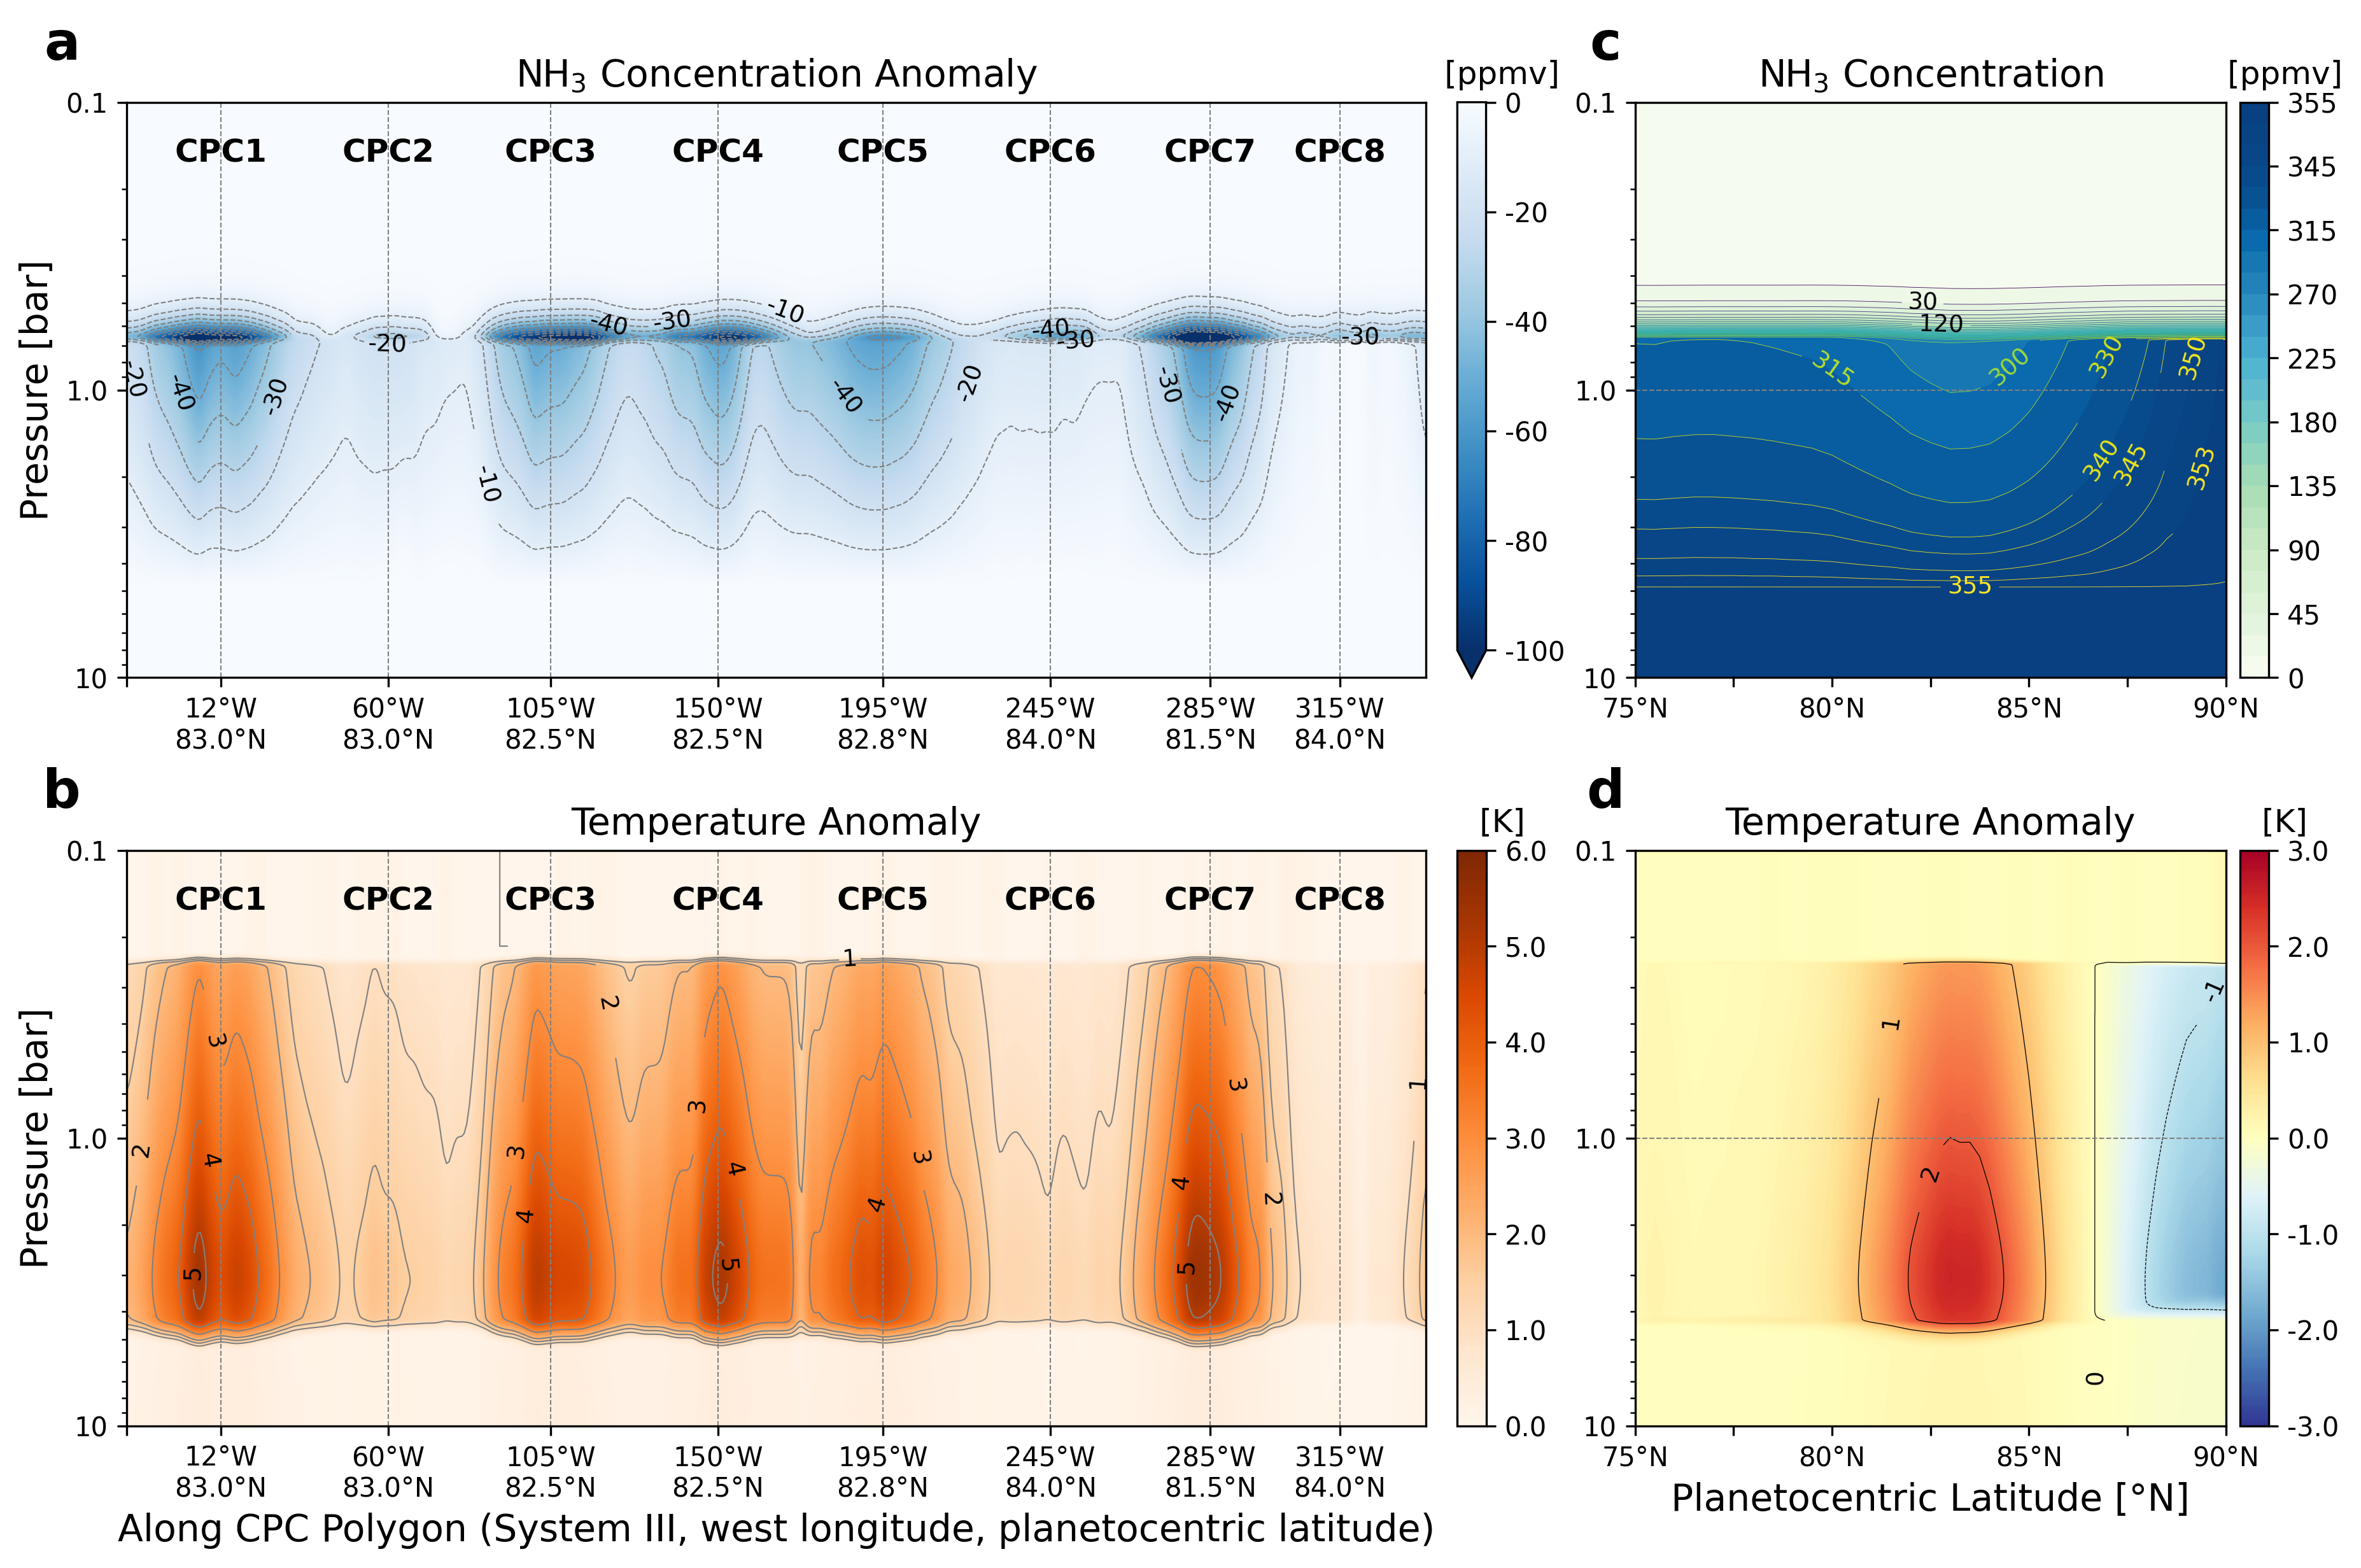

In [17]:



fig, axes= plt.subplots(2,2, figsize=(15,9), dpi=300, gridspec_kw={'width_ratios':[2.2,1], 'wspace':-0.05, 'hspace':0.3})  
axs=axes.flatten()
ax= axs[0]
plot_panela(ax)


######
ax= axs[1]
plot_zonal_nh3(ax)

ax= axs[2]
plot_panel_b(ax)

ax= axs[3]
plot_panel_d(ax)

plt.tight_layout()

plt.savefig("cross_section.pdf",  bbox_inches='tight' ,dpi=100)